# 02 · Modelos · IAQ (Frank)
Sesión 4 · AireIQ · Equipo Novoa

Entrada: **plata** (`data/silver/mediciones_1min`) y el umbral de **oro** (`data/gold/umbral_iaq`).
Salida: modelos ganadores en `models/frank_iaq/` con su JSON de métricas.

1. **Regresión (U1 y U2):** ¿cuál será el IAQ en 5, 10 y 15 minutos? Se compara contra la **persistencia** (repetir el último valor).
2. **Clasificación (U1):** ¿se superará el p95 en la próxima hora?
3. **Reglas:** corte cronológico 80/20 con separación de 60 minutos entre entrenamiento y prueba; `gas_ohms` solo como rezago (valor pasado), nunca el del mismo instante.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import RegressionEvaluator

ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SILVER = ROOT / "data" / "silver" / "mediciones_1min"
GOLD   = ROOT / "data" / "gold"
MODELS = ROOT / "models" / "frank_iaq"
MODELS.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder.appName("aireiq-frank-02").master("local[2]")
         .config("spark.driver.memory", "1g")
         .config("spark.sql.session.timeZone", "America/Lima")
         .config("spark.sql.shuffle.partitions", "8").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

s = spark.read.parquet(str(SILVER)).select("minuto","iaq","temperatura_c","humedad_pct","presion_hpa","gas_ohms","hora")
p95 = spark.read.parquet(str(GOLD / "umbral_iaq")).first()["p95"]
print(f"Minutos en plata: {s.count():,} | umbral p95 = {p95:.2f}")

Minutos en plata: 2,863 | umbral p95 = 32.26


## 1 · Tabla de entrenamiento con rezagos
Los huecos de la serie (sensor apagado, `gas_ohms = 0`) no se rellenan: cada rezago se busca por **tiempo** (`minuto − k`), así que si falta ese minuto la fila se descarta en lugar de inventarse.

In [2]:
def desplazar(col, minutos, nombre):
    # valor de `col` en el minuto (t - minutos), pegado a la fila del minuto t
    return s.select((F.col("minuto") + F.expr(f"INTERVAL {minutos} MINUTES")).alias("minuto"),
                    F.col(col).alias(nombre))

def objetivo(h):
    # valor del IAQ en el minuto (t + h)
    return s.select((F.col("minuto") - F.expr(f"INTERVAL {h} MINUTES")).alias("minuto"),
                    F.col("iaq").alias(f"y_{h}"))

base = (s.join(desplazar("iaq", 5, "iaq_lag5"), "minuto")
          .join(desplazar("iaq", 10, "iaq_lag10"), "minuto")
          .join(desplazar("gas_ohms", 5, "gas_lag5"), "minuto")
          .withColumn("iaq_d5", F.col("iaq") - F.col("iaq_lag5"))
          .withColumn("log_gas_lag5", F.log10("gas_lag5"))
          .withColumn("hora_sin", F.sin(2 * 3.141592653589793 * F.col("hora") / 24))
          .withColumn("hora_cos", F.cos(2 * 3.141592653589793 * F.col("hora") / 24))
          .withColumn("ts", F.unix_timestamp("minuto")))

# Etiqueta de alerta: ¿el IAQ supera el p95 en la próxima hora? (exige al menos 30 minutos observados)
w = Window.orderBy("ts").rangeBetween(60, 3600)
base = (base.withColumn("fut_max", F.max("iaq").over(w))
            .withColumn("fut_n", F.count("iaq").over(w))
            .withColumn("alerta_60", F.when(F.col("fut_n") >= 30, (F.col("fut_max") > p95).cast("int"))))

FEATS_A = ["iaq", "iaq_lag5", "iaq_lag10", "iaq_d5", "temperatura_c", "humedad_pct", "presion_hpa", "hora_sin", "hora_cos"]
FEATS_B = FEATS_A + ["log_gas_lag5"]      # contraste: añade el rezago de gas_ohms
base = base.cache()
print("Filas con rezagos completos:", base.count())

Filas con rezagos completos: 2491


## 2 · Corte cronológico
80 % más antiguo entrena, 20 % más reciente prueba, con **60 minutos de separación** (embargo) para que el objetivo de las últimas filas de entrenamiento no toque el periodo de prueba.

In [3]:
corte = base.approxQuantile("ts", [0.8], 0.001)[0]
EMBARGO = 3600
def partir(df):
    return df.filter(F.col("ts") <= corte - EMBARGO), df.filter(F.col("ts") > corte)

fecha_corte = spark.range(1).select(F.from_unixtime(F.lit(int(corte)))).first()[0]
print("Corte:", fecha_corte)
tr, te = partir(base)
print("Entrenamiento:", tr.count(), "| Prueba:", te.count())

Corte: 2026-11-05 23:10:00
Entrenamiento: 1951 | Prueba: 500


## 3 · Regresión: IAQ a 5, 10 y 15 minutos
Candidatos: persistencia, regresión lineal, Ridge, Elastic Net y Random Forest. **Versión A** = variables ambientales y rezagos del IAQ (la que se defiende). **Versión B** = A más el rezago de `gas_ohms` (contraste).

In [4]:
def candidatos(h):
    y = f"y_{h}"
    return {
        "Lineal":      LinearRegression(featuresCol="x", labelCol=y),
        "Ridge":       LinearRegression(featuresCol="x", labelCol=y, regParam=0.1, elasticNetParam=0.0),
        "ElasticNet":  LinearRegression(featuresCol="x", labelCol=y, regParam=0.1, elasticNetParam=0.5),
        "RandomForest": RandomForestRegressor(featuresCol="x", labelCol=y, numTrees=100, maxDepth=6, seed=42),
    }

def pipeline(feats, modelo):
    return Pipeline(stages=[VectorAssembler(inputCols=feats, outputCol="x_raw", handleInvalid="skip"),
                            StandardScaler(inputCol="x_raw", outputCol="x", withMean=True, withStd=True),
                            modelo])

def metricas(pred, y):
    ev = lambda m: RegressionEvaluator(labelCol=y, predictionCol="prediction", metricName=m).evaluate(pred)
    return ev("rmse"), ev("mae"), ev("r2")

filas, guardados = [], {}
for h in (5, 10, 15):
    y = f"y_{h}"
    tr_h, te_h = tr.join(objetivo(h), "minuto"), te.join(objetivo(h), "minuto")
    # persistencia
    rm, ma, r2 = metricas(te_h.withColumn("prediction", F.col("iaq")), y)
    filas.append(dict(horizonte=h, version="-", modelo="Persistencia", rmse=rm, mae=ma, r2=r2))
    for version, feats in (("A", FEATS_A), ("B", FEATS_B)):
        for nombre, est in candidatos(h).items():
            m = pipeline(feats, est).fit(tr_h)
            rm, ma, r2 = metricas(m.transform(te_h), y)
            filas.append(dict(horizonte=h, version=version, modelo=nombre, rmse=rm, mae=ma, r2=r2))
            guardados[(h, version, nombre)] = m

res = pd.DataFrame(filas)
pers = res[res.modelo == "Persistencia"].set_index("horizonte")["rmse"]
res["mejora_vs_persistencia_%"] = res.apply(lambda r: round(100 * (pers[r.horizonte] - r.rmse) / pers[r.horizonte], 1), axis=1)
res[["rmse", "mae", "r2"]] = res[["rmse", "mae", "r2"]].round(3)
res

,horizonte,version,modelo,rmse,mae,r2,mejora_vs_persistencia_%
0,5,-,Persistencia,3.293,1.572,0.953,0.0
1,5,A,Lineal,3.637,2.311,0.943,-10.4
2,5,A,Ridge,3.762,2.423,0.939,-14.2
3,5,A,ElasticNet,3.637,2.290,0.943,-10.4
4,5,A,RandomForest,7.346,4.749,0.766,-123.1
5,5,B,Lineal,3.638,2.317,0.943,-10.5
6,5,B,Ridge,3.763,2.427,0.939,-14.3
7,5,B,ElasticNet,3.631,2.278,0.943,-10.3
8,5,B,RandomForest,7.507,4.467,0.755,-128.0
9,10,-,Persistencia,5.235,2.480,0.885,0.0


## 4 · Ganador por horizonte (versión A) y guardado

In [5]:
candidatas_A = res[(res.version == "A")]
ganadores = {}
for h in (5, 10, 15):
    sub = candidatas_A[candidatas_A.horizonte == h].sort_values("rmse")
    mejor = sub.iloc[0]
    ganadores[h] = dict(modelo=mejor.modelo, rmse=float(mejor.rmse), mae=float(mejor.mae), r2=float(mejor.r2),
                        rmse_persistencia=float(pers[h]), mejora_pct=float(mejor["mejora_vs_persistencia_%"]),
                        supera_persistencia=bool(mejor.rmse < pers[h]))
    ruta = MODELS / f"iaq_h{h}"
    guardados[(h, "A", mejor.modelo)].write().overwrite().save(str(ruta))
    print(f"h={h:>2} min -> {mejor.modelo:<13} RMSE {mejor.rmse:.3f} vs persistencia {pers[h]:.3f} ({mejor['mejora_vs_persistencia_%']:+.1f} %)  guardado en {ruta.name}")

(MODELS / "metricas_regresion.json").write_text(json.dumps(
    dict(corte=fecha_corte, embargo_s=EMBARGO, predictores=FEATS_A, ganadores=ganadores,
         tabla=res.to_dict(orient="records")), indent=2, ensure_ascii=False))

h= 5 min -> Lineal        RMSE 3.637 vs persistencia 3.293 (-10.4 %)  guardado en iaq_h5
h=10 min -> ElasticNet    RMSE 5.776 vs persistencia 5.235 (-10.3 %)  guardado en iaq_h10
h=15 min -> ElasticNet    RMSE 8.093 vs persistencia 7.871 (-2.8 %)  guardado en iaq_h15


5932

## 5 · Clasificación: ¿se superará el p95 en la próxima hora?
Línea base (persistencia): alertar si el IAQ de ahora ya supera el p95. Se mide con precisión, recall y F1 de la clase *alerta*.

In [6]:
def prf(df, col):
    tp = df.filter((F.col("alerta_60") == 1) & (F.col(col) == 1)).count()
    fp = df.filter((F.col("alerta_60") == 0) & (F.col(col) == 1)).count()
    fn = df.filter((F.col("alerta_60") == 1) & (F.col(col) == 0)).count()
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return round(p, 3), round(r, 3), round(f, 3), tp, fp, fn

trc, tec = tr.filter(F.col("alerta_60").isNotNull()), te.filter(F.col("alerta_60").isNotNull())
print(f"Tasa de alerta  entrenamiento: {trc.agg(F.avg('alerta_60')).first()[0]:.1%}  |  prueba: {tec.agg(F.avg('alerta_60')).first()[0]:.1%}")

filas_c = []
p_, r_, f_, tp, fp, fn = prf(tec.withColumn("pred", (F.col("iaq") > p95).cast("int")), "pred")
filas_c.append(dict(modelo="Persistencia", precision=p_, recall=r_, f1=f_, tp=tp, fp=fp, fn=fn))

clfs = {"Logistica": LogisticRegression(featuresCol="x", labelCol="alerta_60", maxIter=100),
        "RandomForest": RandomForestClassifier(featuresCol="x", labelCol="alerta_60", numTrees=100, maxDepth=6, seed=42)}
mods_c = {}
for nombre, est in clfs.items():
    m = pipeline(FEATS_A, est).fit(trc)
    mods_c[nombre] = m
    p_, r_, f_, tp, fp, fn = prf(m.transform(tec), "prediction")
    filas_c.append(dict(modelo=nombre, precision=p_, recall=r_, f1=f_, tp=tp, fp=fp, fn=fn))
res_c = pd.DataFrame(filas_c)
res_c

Tasa de alerta  entrenamiento: 12.9%  |  prueba: 18.7%


,modelo,precision,recall,f1,tp,fp,fn
0,Persistencia,1.0,1.000,1.000,71,0,0
1,Logistica,1.0,0.944,0.971,67,0,4
2,RandomForest,1.0,0.352,0.521,25,0,46


### Solo anticipación
Si el IAQ **ya** supera el p95, alertar es trivial (la persistencia acierta). La pregunta real es si el modelo avisa cuando el IAQ **todavía está por debajo** y va a superarlo. Esta tabla evalúa solo esos minutos.

In [7]:
tec_ant = tec.filter(F.col("iaq") <= p95)
n_ant, pos_ant = tec_ant.count(), tec_ant.filter(F.col("alerta_60") == 1).count()
print(f"Minutos de prueba con IAQ bajo el p95: {n_ant} | de ellos, con deterioro en la próxima hora: {pos_ant}")

filas_a = []
p_, r_, f_, tp, fp, fn = prf(tec_ant.withColumn("pred", F.lit(0)), "pred")
filas_a.append(dict(modelo="Persistencia (nunca alerta)", precision=p_, recall=r_, f1=f_, tp=tp, fp=fp, fn=fn))
for nombre, m in mods_c.items():
    p_, r_, f_, tp, fp, fn = prf(m.transform(tec_ant), "prediction")
    filas_a.append(dict(modelo=nombre, precision=p_, recall=r_, f1=f_, tp=tp, fp=fp, fn=fn))
res_a = pd.DataFrame(filas_a)
res_a

Minutos de prueba con IAQ bajo el p95: 309 | de ellos, con deterioro en la próxima hora: 0


,modelo,precision,recall,f1,tp,fp,fn
0,Persistencia (nunca alerta),0.0,0.0,0.0,0,0,0
1,Logistica,0.0,0.0,0.0,0,0,0
2,RandomForest,0.0,0.0,0.0,0,0,0


In [8]:
# Si hay deterioros por anticipar en la prueba, el ganador se elige con ellos; si no, con todos los minutos
tabla_gan = res_a[~res_a.modelo.str.startswith("Persistencia")] if pos_ant > 0 else res_c[res_c.modelo != "Persistencia"]
mejor_c = tabla_gan.sort_values("f1", ascending=False).iloc[0]
mods_c[mejor_c.modelo].write().overwrite().save(str(MODELS / "alerta_60min"))
(MODELS / "metricas_alerta.json").write_text(json.dumps(
    dict(umbral_p95=float(p95), ganador=mejor_c.modelo, tabla_todos=res_c.to_dict(orient="records"), tabla_anticipacion=res_a.to_dict(orient="records"), minutos_anticipacion=int(n_ant), deterioros_anticipables=int(pos_ant)), indent=2, ensure_ascii=False))
print("Ganador de la alerta:", mejor_c.modelo, "| F1 =", mejor_c.f1)

Ganador de la alerta: Logistica | F1 = 0.971


## 6 · Probar el modelo guardado (sin reentrenar)

RMSE del modelo cargado: 5.776


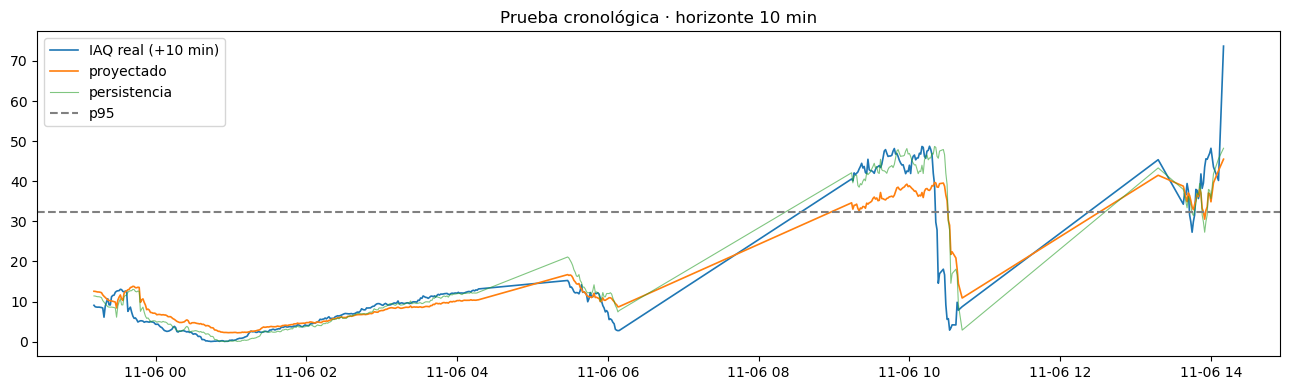

In [9]:
H = 10
m = PipelineModel.load(str(MODELS / f"iaq_h{H}"))
te_h = te.join(objetivo(H), "minuto")
pred = m.transform(te_h)
print("RMSE del modelo cargado:", round(RegressionEvaluator(labelCol=f"y_{H}", predictionCol="prediction", metricName="rmse").evaluate(pred), 3))

pdf = pred.select("minuto", "iaq", f"y_{H}", "prediction").orderBy("minuto").toPandas()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(pdf["minuto"], pdf[f"y_{H}"], label=f"IAQ real (+{H} min)", lw=1.2)
ax.plot(pdf["minuto"], pdf["prediction"], label="proyectado", lw=1.2)
ax.plot(pdf["minuto"], pdf["iaq"], label="persistencia", lw=0.8, alpha=0.6)
ax.axhline(p95, ls="--", c="gray", label="p95"); ax.legend(); ax.set_title(f"Prueba cronológica · horizonte {H} min")
plt.tight_layout(); plt.show()

In [10]:
# Lectura inventada: ¿qué proyecta el modelo guardado?
una = spark.createDataFrame([dict(iaq=24.0, iaq_lag5=21.0, iaq_lag10=18.0, iaq_d5=3.0,
                                  temperatura_c=21.5, humedad_pct=45.0, presion_hpa=647.3,
                                  hora_sin=0.5, hora_cos=-0.87)])
m.transform(una).select("iaq", "prediction").show()

+----+-----------------+
| iaq|       prediction|
+----+-----------------+
|24.0|19.98493601879772|
+----+-----------------+

